# Project 1, Part A (continued): V1 to V5, looking inside

Needs the checkpoints and `my_models.py` from P1_A. For each figure, state the selection rule, the normalization, and a supported claim.
Leave crops flagged by `HAS_PERSON` out of every figure.

On Colab, start in a fresh session (Runtime > Disconnect and delete runtime in the previous notebook), and finish the Google Drive pop-up that the first cell opens.

Write your own training, evaluation, and visualization code (PyTorch, torchvision, OpenCV, scikit-learn, timm). A1 to A5 use no pretrained weights. AI tools may help you study; they may not write your code or report.

Library functions are listed in each step below, and in full in the handout's Appendix A.

In [12]:
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:                 # every notebook of the project shares one folder on your Google Drive
    from google.colab import drive
    try:                     # a sign-in pop-up opens: finish it within 10 minutes (Colab's default is 2)
        drive.mount('/content/drive', timeout_ms=600_000)
    except Exception as e:
        raise RuntimeError('Google Drive did not mount. Run this cell again and finish the sign-in pop-up, '
                           'with the same Google account in every notebook.') from e
ROOT = os.environ.get('P1_ROOT') or ('/content/drive/MyDrive/p1' if IN_COLAB else os.path.abspath('p1'))
os.environ['P1_ROOT'] = ROOT
os.makedirs(ROOT, exist_ok=True)
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)
print('project folder:', ROOT)
assert os.path.exists(os.path.join(ROOT, 'p1_utils.py')), 'Run P1_0_Setup_and_Data.ipynb first: it writes p1_utils.py.'
from p1_utils import *
print_versions()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
project folder: /content/drive/MyDrive/p1
versions: python 3.13.16, torch 2.14.1+cu130, torchvision 0.29.1+cu130, timm 1.0.30, numpy 2.4.6, scikit-learn 1.6.1, pandas 2.2.3, matplotlib 3.10.0, pillow 11.3.0, pillow-heif 1.8.1, opencv 4.14.0, gpu Tesla T4


{'python': '3.13.16',
 'torch': '2.14.1+cu130',
 'torchvision': '0.29.1+cu130',
 'timm': '1.0.30',
 'numpy': '2.4.6',
 'scikit-learn': '1.6.1',
 'pandas': '2.2.3',
 'matplotlib': '3.10.0',
 'pillow': '11.3.0',
 'pillow-heif': '1.8.1',
 'opencv': '4.14.0',
 'gpu': 'Tesla T4'}

In [13]:
import torch, torch.nn as nn, torch.nn.functional as F
DEV = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
print('device:', DEV)
MY_CLASSES = ['bicycle', 'bottle', 'chair', 'car', 'cat']     # TODO: your five classes (same in every notebook)

CKPT_DIR = "/content/drive/MyDrive/p1/checkpoints"

device: cuda


In [14]:
X64, y, img_id, is_test = load_crops(64)          # cached by P1_0
idx_train, idx_val, idx_test = make_splits(img_id, is_test)
HAS_PERSON = person_flags()                       # leave these crops out of every figure
print(len(idx_train), 'train,', len(idx_val), 'validation,', len(idx_test), 'test crops')

7541 train, 797 validation, 8381 test crops


In [15]:
try:                                              # your classes and helpers, written in P1_A
    from my_models import *
except ImportError:
    print('my_models.py not found yet: write it in P1_A_Classifier_Ladder')

In [16]:
# TODO Load your A1 (three L2 settings), A3, A4, A5 and A6-H from CKPT_DIR.
# Functions: model.load_state_dict(torch.load(path, map_location=DEV)); model.to(DEV).eval()
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

from my_models import (
    A1Linear, A3MLP, A4ResNet, A5ViT, A6ViT,
    resize_a1, preprocess_a1, preprocess_a3, preprocess_a4, preprocess_a6,
)

ckpt_dir = Path(CKPT_DIR)
results_dir = Path(globals().get("RESULTS_DIR", ckpt_dir.parent / "results"))


def load_checkpoint(model, filename):
    path = ckpt_dir / filename
    state = torch.load(path, map_location="cpu", weights_only=True)
    model.load_state_dict(state, strict=True)
    model = model.to(DEV).eval()
    print(f"Loaded {filename} on {DEV}")
    return model


A1_MODELS = {}
for l2, tag in [(0.01, "0.01"), (1.0, "1"), (10.0, "10")]:
    A1_MODELS[l2] = load_checkpoint(A1Linear(), f"a1_l2_{tag}.pt")

A3_MODEL = load_checkpoint(A3MLP(), "a3.pt")
A4_MODEL = load_checkpoint(A4ResNet(), "a4.pt")
A5_MODEL = load_checkpoint(A5ViT(), "a5.pt")
A6_H_MODEL = load_checkpoint(A6ViT(pretrained=False), "a6_h.pt")

Loaded a1_l2_0.01.pt on cuda
Loaded a1_l2_1.pt on cuda
Loaded a1_l2_10.pt on cuda
Loaded a3.pt on cuda
Loaded a4.pt on cuda
Loaded a5.pt on cuda
Loaded a6_h.pt on cuda


In [17]:
# TODO Reload check, before using any reloaded model: recompute its VOC test mean per-class accuracy (19 classes)
# and confirm it matches Table 1 from P1_A. If it does not, this notebook's preprocessing differs from P1_A's
# (for example, A6 needs its checkpoint's mean and std, not the usual ImageNet values): fix that first.
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

from my_models import (
    resize_a1,
    preprocess_a1,
    preprocess_a3,
    preprocess_a4,
    preprocess_a6,
)


ckpt_dir = Path(CKPT_DIR)
results_dir = Path(globals().get("RESULTS_DIR", ckpt_dir.parent / "results"))

table_path = results_dir / "table1.csv"
table1 = pd.read_csv(table_path).set_index("model")

acc_column = "mean_class_test_acc_pct"
required_rows = ["A1", "A3", "A4", "A5", "A6-H"]
reference = table1.loc[required_rows, acc_column].astype(float)

if not reference.index.is_unique or not np.isfinite(reference).all():
    raise ValueError("Table 1 must contain one finite accuracy per required model.")


def load_stats(filename):
    with np.load(ckpt_dir / filename) as data:
        return data["mean"], data["std"]


mean32, std32 = load_stats("a1_stats.npz")
mean64, std64 = load_stats("a4_stats.npz")
mean224, std224 = load_stats("a6_h_stats.npz")

with np.load(ckpt_dir / "a3_test.npz") as saved:
    a3_saved_per_class_pct = 100.0 * np.asarray(
        saved["per_class_acc"], dtype=np.float64
    ).reshape(19)
    a3_saved_mean_pct = 100.0 * float(saved["mean_per_class_acc"].item())




def prepare_a1(images):
    return preprocess_a1(resize_a1(images), mean32, std32)


def prepare_a3(images):
    return preprocess_a3(images, mean32, std32)


def prepare_64(images):
    return preprocess_a4(images, mean64, std64)


def prepare_a6_h(images):
    return preprocess_a6(images, mean224, std224, DEV)


if not all(name in globals() for name in ("X224", "y224", "img_id224", "is_test224")):
    X224, y224, img_id224, is_test224 = load_crops(224)

if not (
    np.array_equal(y224, y)
    and np.array_equal(img_id224, img_id)
    and np.array_equal(is_test224, is_test)
):
    raise ValueError("The 224×224 crops do not align with the 64×64 crops.")


N_CLASSES = 19
labels = np.asarray(y).reshape(-1)
test_indices = np.asarray(idx_test).reshape(-1)

if test_indices.dtype == bool:
    test_indices = np.flatnonzero(test_indices)

test_labels = labels[test_indices]
if not np.isin(test_labels, np.arange(N_CLASSES)).all():
    raise ValueError("Expected VOC class IDs from 0 through 18.")

test_labels = test_labels.astype(np.int64)
class_totals = np.bincount(test_labels, minlength=N_CLASSES)

if (class_totals == 0).any():
    missing = np.flatnonzero(class_totals == 0).tolist()
    raise ValueError(f"Test split has no samples for class IDs {missing}.")


@torch.inference_mode()
def evaluate_reload(model, images, prepare, batch_size=32):
    model.eval()
    correct = np.zeros(N_CLASSES, dtype=np.int64)

    for start in range(0, len(test_indices), batch_size):
        stop = start + batch_size
        ids = test_indices[start:stop]
        target = test_labels[start:stop]

        xb = prepare(images[ids]).to(DEV)
        logits = model(xb)
        if logits.shape != (len(ids), N_CLASSES):
            raise ValueError(f"Unexpected logits shape: {tuple(logits.shape)}")

        pred = logits.argmax(dim=1).cpu().numpy()
        correct += np.bincount(target[pred == target], minlength=N_CLASSES)

    return 100.0 * correct / class_totals



checks = [
    ("A1 (L2=0.01)", None,   A1_MODELS[0.01], X64,  prepare_a1),
    ("A1 (L2=1)",    "A1",   A1_MODELS[1.0],  X64,  prepare_a1),
    ("A1 (L2=10)",   None,   A1_MODELS[10.0], X64,  prepare_a1),
    ("A3",           "A3",   A3_MODEL,        X64,  prepare_a3),
    ("A4",           "A4",   A4_MODEL,        X64,  prepare_64),
    ("A5",           "A5",   A5_MODEL,        X64,  prepare_64),
    ("A6-H",         "A6-H", A6_H_MODEL,      X224, prepare_a6_h),
]

table_atol = 0.000051
per_class_results = {}
rows = []

for name, table_row, model, images, prepare in checks:
    class_acc = evaluate_reload(model, images, prepare)
    per_class_results[name] = class_acc
    actual = float(class_acc.mean())

    expected = np.nan
    delta = np.nan
    status = "NO TABLE ROW"

    if table_row is not None:
        expected = float(reference.loc[table_row])
        delta = actual - expected
        status = "PASS" if abs(delta) <= table_atol else "FAIL"

    if name == "A3":
        a3_classes_match = np.allclose(
            class_acc, a3_saved_per_class_pct, atol=1e-5, rtol=0
        )
        if not a3_classes_match:
            status = "FAIL"

    rows.append({
        "model": name,
        "reload_acc_pct": actual,
        "table1_acc_pct": expected,
        "delta_pct_points": delta,
        "status": status,
    })

reload_check = pd.DataFrame(rows).set_index("model")
display(reload_check.round(6))


if reload_check.loc["A3", "status"] == "FAIL":
    print(f"\nA3 saved P1_A test mean: {a3_saved_mean_pct:.8f}%")
    print(f"A3 Table 1 test mean:    {reference.loc['A3']:.8f}%")
    print(f"A3 reloaded test mean:   {reload_check.loc['A3', 'reload_acc_pct']:.8f}%")

    a3_comparison = pd.DataFrame({
        "class_id": np.arange(N_CLASSES),
        "P1_A_acc_pct": a3_saved_per_class_pct,
        "reload_acc_pct": per_class_results["A3"],
    })
    a3_comparison["delta_pct_points"] = (
        a3_comparison["reload_acc_pct"] - a3_comparison["P1_A_acc_pct"]
    )

    changed = a3_comparison["delta_pct_points"].abs() > 1e-5
    display(a3_comparison.loc[changed].round(4))

failed = reload_check.index[reload_check["status"] == "FAIL"].tolist()
if failed:
    raise AssertionError("Reload check failed for: " + ", ".join(failed))

print("PASS: all five models with a Table 1 reference matched.")

,reload_acc_pct,table1_acc_pct,delta_pct_points,status
model,,,,
A1 (L2=0.01),20.623743,NaN,NaN,NO TABLE ROW
A1 (L2=1),16.069315,16.0693,0.000015,PASS
A1 (L2=10),11.546091,NaN,NaN,NO TABLE ROW
A3,23.659833,23.6598,0.000033,PASS
A4,54.968051,54.9681,-0.000049,PASS
A5,33.996846,33.9968,0.000046,PASS
A6-H,92.199187,92.1992,-0.000013,PASS


PASS: all five models with a Table 1 reference matched.


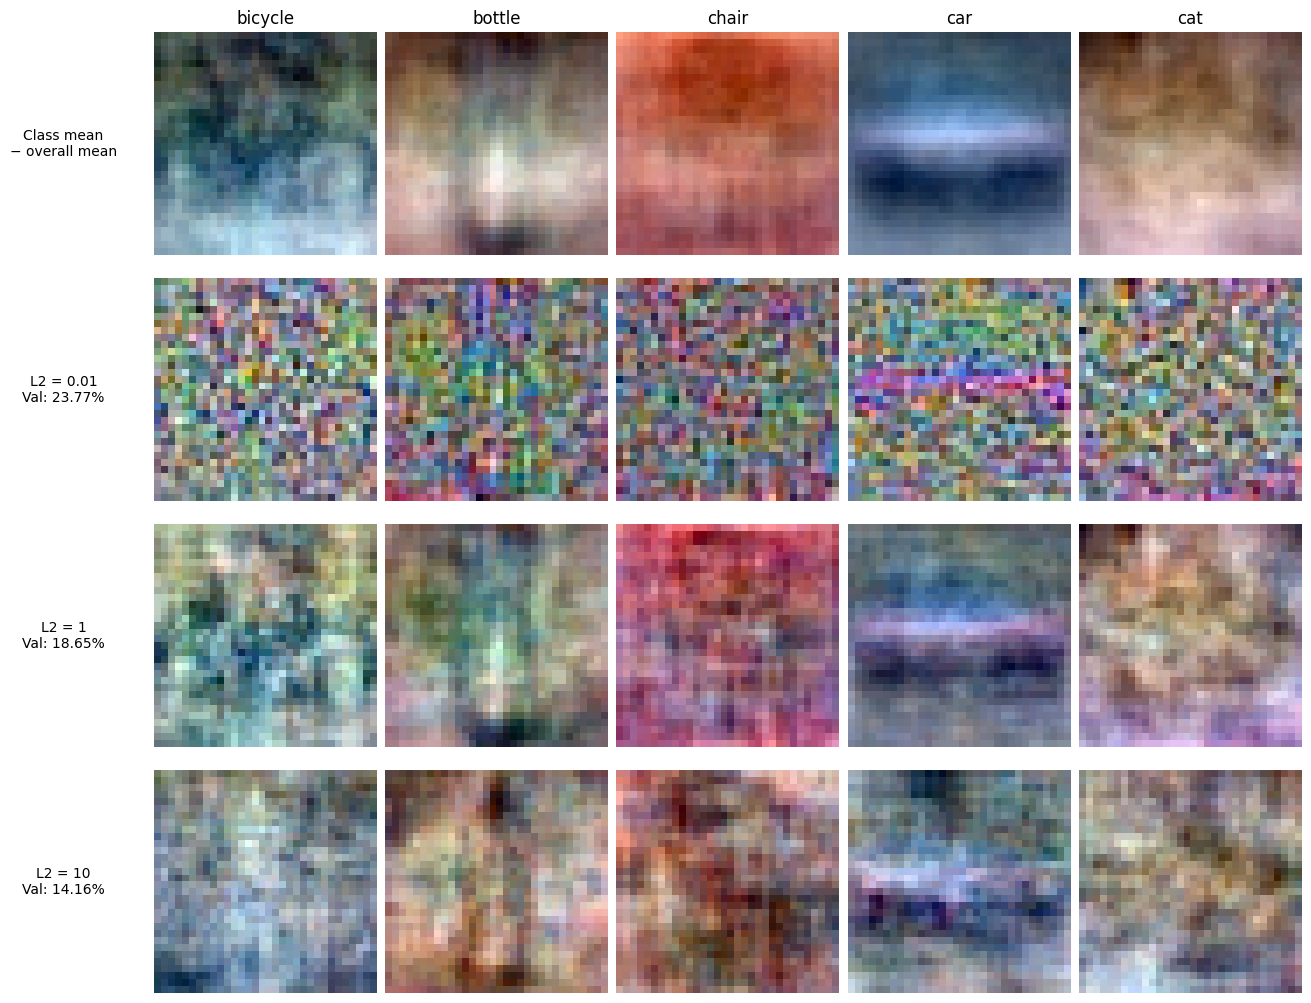

In [18]:
# TODO V1: A1 weights at the three L2 settings, reshaped to 32x32x3 for your five classes, each template scaled to its own
# range, (w - w.min()) / (w.max() - w.min()); validation accuracy of each. Above them, each class's mean training crop minus
# the mean of all training crops. Describe how the weights change across the settings, and whether the most readable is the most accurate.
# Functions: layer.weight.detach().cpu().numpy(); w.reshape(32, 32, 3); (w - w.min()) / (w.max() - w.min());
#    X[idx_train][y[idx_train] == c].mean(axis=0); plt.subplots(rows, cols); ax.imshow
import numpy as np
import matplotlib.pyplot as plt
from my_models import resize_a1

class_to_id = {
    "bicycle": 1,
    "bottle": 4,
    "chair": 8,
    "car": 6,
    "cat": 7,
}

y_array = np.asarray(y)
train_indices = np.asarray(idx_train)

expected_counts = {
    "bicycle": 312,
    "bottle": 299,
    "chair": 1005,
    "car": 681,
    "cat": 546,
}

for name in MY_CLASSES:
    count = np.count_nonzero(
        y_array[train_indices] == class_to_id[name]
    )

val_acc = {
    0.01: 0.2377,
    1.0: 0.1865,
    10.0: 0.1416,
}


def scale_for_display(image):
    image = np.asarray(image, dtype=np.float32)
    low = image.min()
    high = image.max()

    if high == low:
        return np.zeros_like(image)

    return (image - low) / (high - low)

figure_indices = np.asarray(idx_train)

figure_crops = resize_a1(
    X64[figure_indices]
).astype(np.float32)

figure_labels = np.asarray(y)[figure_indices]

overall_mean = figure_crops.mean(axis=0)

fig, axes = plt.subplots(
    4, 5,
    figsize=(13, 10),
    constrained_layout=True,
)

for col, name in enumerate(MY_CLASSES):
    mask = figure_labels == class_to_id[name]

    class_mean = figure_crops[mask].mean(axis=0)
    difference = class_mean - overall_mean

    axes[0, col].imshow(scale_for_display(difference))
    axes[0, col].set_title(name)

axes[0, 0].set_ylabel(
    "Class mean\n− overall mean",
    rotation=0,
    labelpad=65,
    va="center",
)

for row, l2 in enumerate((0.01, 1.0, 10.0), start=1):
    weights = (
        A1_MODELS[l2].linear.weight
        .detach().cpu().numpy()
    )

    for col, name in enumerate(MY_CLASSES):
        class_id = class_to_id[name]
        template = weights[class_id].reshape(3, 32, 32)
        template = template.transpose(1, 2, 0)

        axes[row, col].imshow(scale_for_display(template))

    axes[row, 0].set_ylabel(
        f"L2 = {l2:g}\nVal: {val_acc[l2]:.2%}",
        rotation=0,
        labelpad=65,
        va="center",
    )

for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

plt.show()

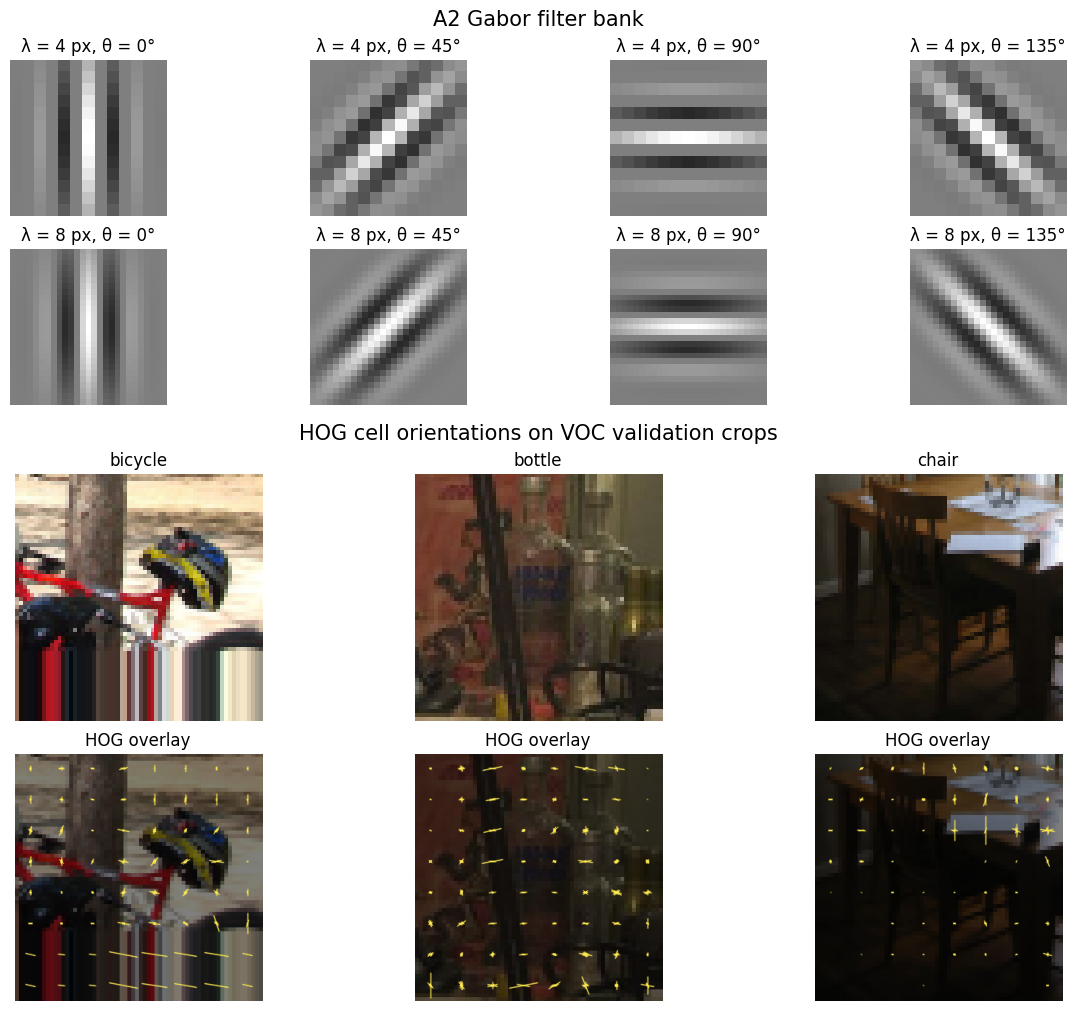

Saved: /content/drive/MyDrive/p1/results/V2.png


In [19]:
# TODO V2: the Gabor bank, and HOG cell-orientation histograms drawn over three VOC crops. Compute the per-cell histograms
# yourself (cv2.Sobel, cv2.cartToPolar, np.bincount over 8x8 cells): cv2.HOGDescriptor returns one long vector.
# Functions: cv2.getGaborKernel; cv2.Sobel(gray, cv2.CV_32F, 1, 0); cv2.cartToPolar(gx, gy, angleInDegrees=True);
#    np.bincount(bins, weights=mag, minlength=9); cv2.line
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

results_dir = Path(globals().get("RESULTS_DIR", Path(CKPT_DIR).parent / "results"))
results_dir.mkdir(parents=True, exist_ok=True)



angles_deg = [0, 45, 90, 135]
gabor_settings = [(4, 13), (8, 27)]

gabor_bank = {}
for angle in angles_deg:
    for wavelength, size in gabor_settings:
        kernel = cv2.getGaborKernel(
            ksize=(size, size),
            sigma=0.56 * wavelength,
            theta=np.deg2rad(angle),
            lambd=float(wavelength),
            gamma=0.5,
            psi=0.0,
            ktype=cv2.CV_32F,
        )
        kernel -= kernel.mean()
        gabor_bank[angle, wavelength] = kernel



def hog_cell_histograms(rgb):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(np.float32)
    gx = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)

    mag, angle = cv2.cartToPolar(gx, gy, angleInDegrees=True)
    angle = angle % 180.0
    bins = np.minimum((angle / 20.0).astype(np.int32), 8)

    cell_size = 8
    n_rows = gray.shape[0] // cell_size
    n_cols = gray.shape[1] // cell_size
    hist = np.zeros((n_rows, n_cols, 9), dtype=np.float32)

    for row in range(n_rows):
        for col in range(n_cols):
            ys = slice(row * cell_size, (row + 1) * cell_size)
            xs = slice(col * cell_size, (col + 1) * cell_size)
            hist[row, col] = np.bincount(
                bins[ys, xs].ravel(),
                weights=mag[ys, xs].ravel(),
                minlength=9,
            )

    return hist


def draw_hog_overlay(rgb, hist, scale=5):
    height, width = rgb.shape[:2]
    canvas = cv2.resize(
        rgb, (width * scale, height * scale),
        interpolation=cv2.INTER_NEAREST,
    )
    canvas = (canvas * 0.50).astype(np.uint8)

    peak = float(hist.max())
    if peak == 0:
        return canvas

    cell_px = 8 * scale
    bin_centers = np.deg2rad(np.arange(10, 180, 20))

    for row in range(hist.shape[0]):
        for col in range(hist.shape[1]):
            cx = (col + 0.5) * cell_px - 0.5
            cy = (row + 0.5) * cell_px - 0.5

            for strength, theta in zip(hist[row, col], bin_centers):
                half_length = 0.47 * cell_px * float(strength) / peak
                if half_length < 0.5:
                    continue

                dx = half_length * np.cos(theta)
                dy = half_length * np.sin(theta)
                p1 = (round(cx - dx), round(cy - dy))
                p2 = (round(cx + dx), round(cy + dy))
                cv2.line(canvas, p1, p2, (255, 235, 80), 1, cv2.LINE_AA)

    return canvas


class_to_id = {"bicycle": 1, "bottle": 4, "chair": 8, "car": 6, "cat": 7}
labels = np.asarray(y).reshape(-1)
has_person = np.asarray(HAS_PERSON, dtype=bool).reshape(-1)

val_ids = np.asarray(idx_val).reshape(-1)
if val_ids.dtype == bool:
    val_ids = np.flatnonzero(val_ids)

eligible = val_ids[~has_person[val_ids]]
rng = np.random.default_rng(42)
examples = []

for name in MY_CLASSES[:3]:
    candidates = eligible[labels[eligible] == class_to_id[name]]
    if candidates.size == 0:
        raise ValueError(f"No person-free validation crop found for {name}.")
    examples.append((name, int(rng.choice(candidates))))



fig = plt.figure(figsize=(12, 10), constrained_layout=True)
sections = fig.subfigures(2, 1, height_ratios=[1, 1.45])

sections[0].suptitle("A2 Gabor filter bank", fontsize=15)
gabor_axes = sections[0].subplots(2, 4)

for row, (wavelength, size) in enumerate(gabor_settings):
    for col, angle in enumerate(angles_deg):
        ax = gabor_axes[row, col]
        kernel = gabor_bank[angle, wavelength]
        limit = np.abs(kernel).max()
        ax.imshow(kernel, cmap="gray", vmin=-limit, vmax=limit,
                  interpolation="nearest")
        ax.set_title(f"λ = {wavelength} px, θ = {angle}°")
        ax.axis("off")

sections[1].suptitle("HOG cell orientations on VOC validation crops", fontsize=15)
hog_axes = sections[1].subplots(2, 3)

for col, (name, crop_id) in enumerate(examples):
    rgb = np.asarray(X64[crop_id])
    hist = hog_cell_histograms(rgb)

    hog_axes[0, col].imshow(rgb, interpolation="nearest")
    hog_axes[0, col].set_title(name)
    hog_axes[1, col].imshow(draw_hog_overlay(rgb, hist))
    hog_axes[1, col].set_title("HOG overlay")

    for ax in hog_axes[:, col]:
        ax.axis("off")

output_path = results_dir / "V2.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {output_path}")

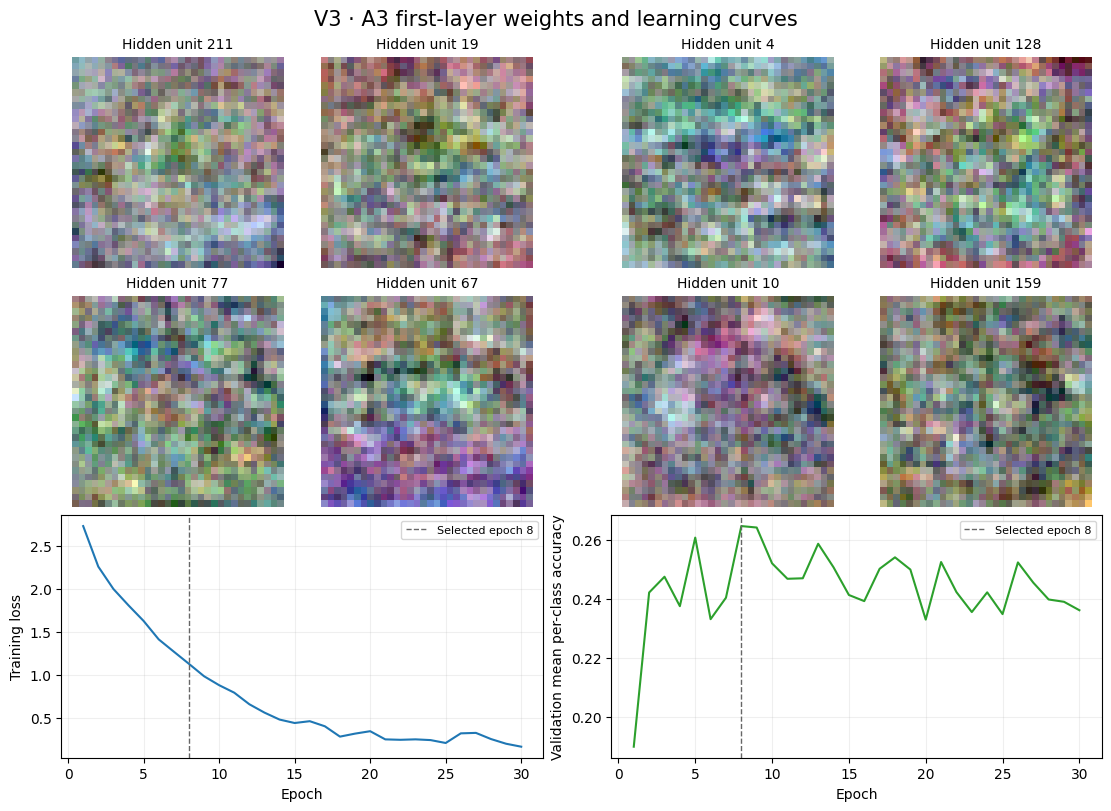

Selected hidden units: [211, 19, 4, 128, 77, 67, 10, 159]
Saved: /content/drive/MyDrive/p1/results/V3.png


In [20]:
# TODO V3: eight first-layer MLP units, chosen with a fixed seed before you look, reshaped to RGB images. Compare with V1 and
# with A3's learning curves: class templates, or fits to individual training images?
# Functions: np.random.default_rng(0).choice(256, 8, replace=False); layer.weight.detach().cpu().numpy()
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn


if reload_check.loc["A3", "status"] != "PASS":
    raise RuntimeError(
        "A3 has not passed the reload check. "
        "Resolve the A3 mismatch and rerun the reload check before generating V3."
    )

ckpt_dir = Path(CKPT_DIR)
results_dir = Path(globals().get("RESULTS_DIR", ckpt_dir.parent / "results"))
results_dir.mkdir(parents=True, exist_ok=True)


first_layer = next(m for m in A3_MODEL.modules() if isinstance(m, nn.Linear))
weights = first_layer.weight.detach().cpu().numpy()

if weights.shape != (256, 3 * 32 * 32):
    raise ValueError(f"Expected A3 first-layer weights of shape (256, 3072), got {weights.shape}.")

unit_ids = np.random.default_rng(0).choice(256, 8, replace=False)

templates = weights[unit_ids].reshape(8, 3, 32, 32).transpose(0, 2, 3, 1)

low = templates.min(axis=(1, 2, 3), keepdims=True)
high = templates.max(axis=(1, 2, 3), keepdims=True)
templates = (templates - low) / np.maximum(high - low, 1e-12)


with np.load(ckpt_dir / "a3_history.npz") as history:
    epochs = history["epoch"]
    train_loss = history["train_loss"]
    val_acc = history["val_mean_per_class_acc"]

with np.load(ckpt_dir / "a3_test.npz") as result:
    best_epoch = int(result["best_epoch"].item())


fig = plt.figure(figsize=(11, 8), constrained_layout=True)
grid = fig.add_gridspec(3, 4, height_ratios=[1, 1, 1.15])
fig.suptitle("V3 · A3 first-layer weights and learning curves", fontsize=15)

for i, (unit_id, template) in enumerate(zip(unit_ids, templates)):
    ax = fig.add_subplot(grid[i // 4, i % 4])
    ax.imshow(template, interpolation="nearest")
    ax.set_title(f"Hidden unit {unit_id}", fontsize=10)
    ax.axis("off")

ax_loss = fig.add_subplot(grid[2, :2])
ax_val = fig.add_subplot(grid[2, 2:])

ax_loss.plot(epochs, train_loss, color="tab:blue")
ax_loss.set(xlabel="Epoch", ylabel="Training loss")

ax_val.plot(epochs, val_acc, color="tab:green")
ax_val.set(xlabel="Epoch", ylabel="Validation mean per-class accuracy")

for ax in (ax_loss, ax_val):
    ax.axvline(best_epoch, color="0.4", linestyle="--",
               linewidth=1, label=f"Selected epoch {best_epoch}")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

output_path = results_dir / "V3.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()

print("Selected hidden units:", unit_ids.tolist())
print("Saved:", output_path)

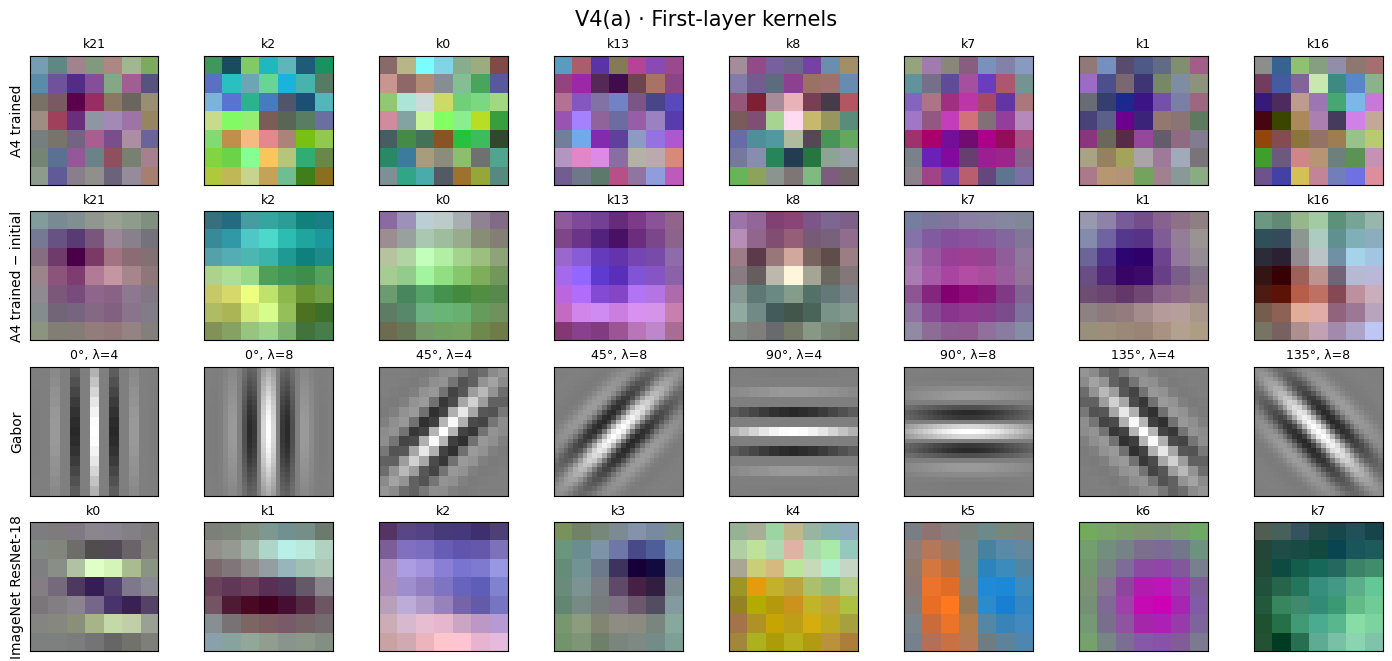

Selected channels: {'stage1': [19, 16, 25], 'stage2': [1, 4, 2], 'stage3': [81, 64, 115]}


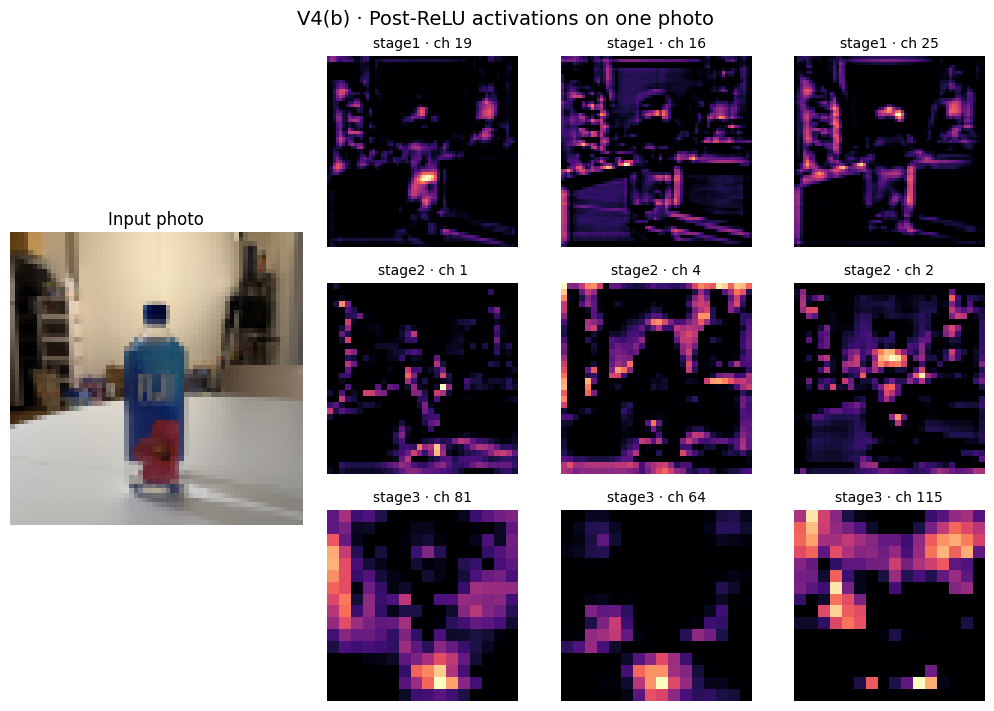

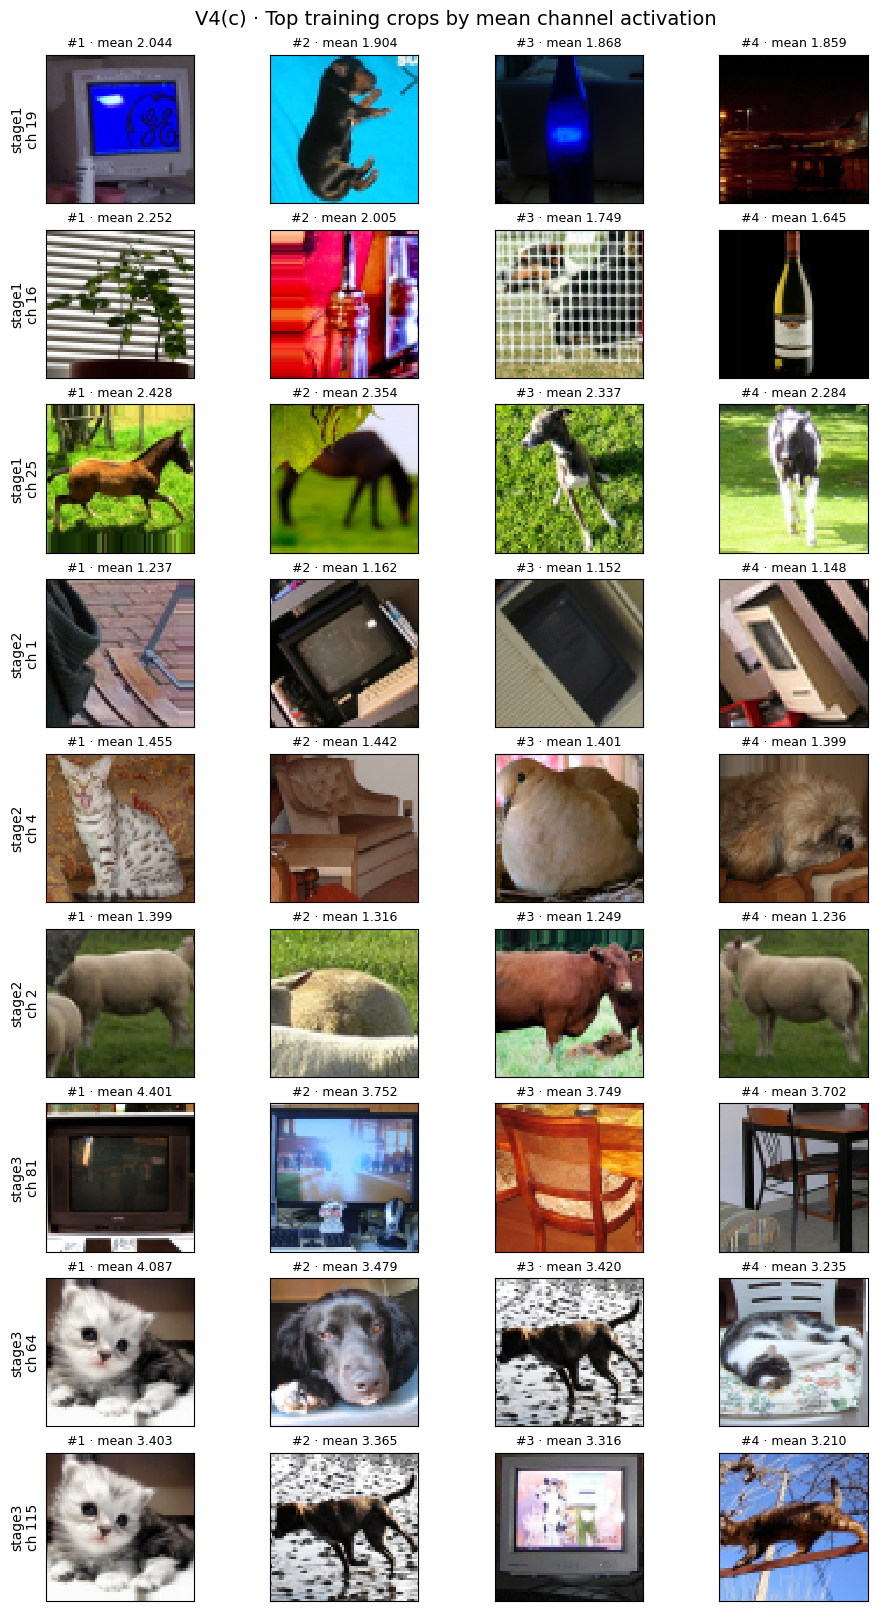

Ranked 5906 person-free training crops.
Saved figures to: /content/drive/MyDrive/p1/results


In [24]:
# TODO V4: (a) eight A4 first-layer kernels chosen with a fixed seed, after training and as final minus initial weights, beside
# the Gabor bank and the first eight ImageNet ResNet-18 first-layer kernels (each kernel gray at zero: 0.5 + 0.5 * w / abs(w).max());
# (b) three channels per residual stage for one of your photos (channels chosen with a fixed seed);
# (c) for the same channels, the four training crops without people (not HAS_PERSON) with the highest spatial mean of the
# post-ReLU stage activation (36 crops).
# Functions: torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1);
#    r18.conv1.weight; load_photo(path, 64); stage.register_forward_hook(fn); act.mean(dim=(2, 3)); np.argsort
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torchvision.models import resnet18, ResNet18_Weights
from my_models import preprocess_a4

if reload_check.loc["A4", "status"] != "PASS":
    raise RuntimeError("Run the A4 reload check successfully before V4.")

ckpt_dir = Path(CKPT_DIR)
results_dir = Path(globals().get("RESULTS_DIR", ckpt_dir.parent / "results"))
results_dir.mkdir(parents=True, exist_ok=True)

A4_MODEL.eval()

trained_w = A4_MODEL.stem_conv.weight.detach().cpu().numpy()
initial_state = torch.load(
    ckpt_dir / "a4_initial.pt", map_location="cpu", weights_only=True
)
initial_w = initial_state["stem_conv.weight"].numpy()

if initial_w.shape != trained_w.shape:
    raise ValueError("Initial and trained A4 stem weights have different shapes.")

kernel_ids = np.random.default_rng(0).choice(
    len(trained_w), size=8, replace=False
)

r18 = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
imagenet_w = r18.conv1.weight[:8].detach().cpu().numpy()
del r18

gabor_keys = [
    (angle, wavelength)
    for angle in (0, 45, 90, 135)
    for wavelength in (4, 8)
]


def kernel_image(w):
    """Convert a signed 2D or CHW kernel to an image with zero at mid-gray."""
    w = np.asarray(w)
    if w.ndim == 3:
        w = np.moveaxis(w, 0, -1)

    peak = np.abs(w).max()
    if peak == 0:
        return np.full(w.shape, 0.5, dtype=np.float32)
    return np.clip(0.5 + 0.5 * w / peak, 0, 1)


kernel_rows = [
    (
        "A4 trained",
        trained_w[kernel_ids],
        [f"k{i}" for i in kernel_ids],
    ),
    (
        "A4 trained − initial",
        (trained_w - initial_w)[kernel_ids],
        [f"k{i}" for i in kernel_ids],
    ),
    (
        "Gabor",
        [gabor_bank[key] for key in gabor_keys],
        [f"{angle}°, λ={wave}" for angle, wave in gabor_keys],
    ),
    (
        "ImageNet ResNet-18",
        imagenet_w,
        [f"k{i}" for i in range(8)],
    ),
]

fig, axes = plt.subplots(4, 8, figsize=(14, 6.5), constrained_layout=True)

for row, (label, kernels, titles) in enumerate(kernel_rows):
    for col, (kernel, title) in enumerate(zip(kernels, titles)):
        ax = axes[row, col]
        ax.imshow(
            kernel_image(kernel), cmap="gray", vmin=0, vmax=1,
            interpolation="nearest",
        )
        ax.set_title(title, fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(label, fontsize=10)

fig.suptitle("V4(a) · First-layer kernels", fontsize=15)
fig.savefig(results_dir / "V4a.png", dpi=200, bbox_inches="tight")
plt.show()

PHOTO_PATH = Path("/content/drive/MyDrive/p1/photos/V4b.jpg")

if not PHOTO_PATH.is_file():
    raise FileNotFoundError(f"Set PHOTO_PATH to one of your own photos: {PHOTO_PATH}")

photo = np.asarray(load_photo(str(PHOTO_PATH), 64))
if photo.shape != (64, 64, 3):
    raise ValueError(f"Expected a 64×64 RGB photo, got {photo.shape}.")

with np.load(ckpt_dir / "a4_stats.npz") as stats:
    a4_mean, a4_std = stats["mean"], stats["std"]

stages = {
    "stage1": A4_MODEL.stage1,
    "stage2": A4_MODEL.stage2,
    "stage3": A4_MODEL.stage3,
}
stage_widths = {"stage1": 32, "stage2": 64, "stage3": 128}

rng = np.random.default_rng(0)
stage_channels = {
    name: rng.choice(width, size=3, replace=False).tolist()
    for name, width in stage_widths.items()
}
print("Selected channels:", stage_channels)


def selected_stage_outputs(rgb_batch):
    """Return the three selected post-ReLU feature maps from each A4 stage."""
    outputs = {}
    handles = []

    def make_hook(name):
        def capture(module, inputs, output):
            outputs[name] = output[:, stage_channels[name], :, :].detach()
        return capture

    try:
        for name, stage in stages.items():
            handles.append(stage.register_forward_hook(make_hook(name)))

        with torch.inference_mode():
            xb = preprocess_a4(rgb_batch, a4_mean, a4_std).to(DEV)
            A4_MODEL(xb)
    finally:
        for handle in handles:
            handle.remove()

    return outputs


photo_acts = selected_stage_outputs(photo[None, ...])

fig = plt.figure(figsize=(10, 7), constrained_layout=True)
grid = fig.add_gridspec(3, 4, width_ratios=[1.3, 1, 1, 1])

ax_photo = fig.add_subplot(grid[:, 0])
ax_photo.imshow(photo)
ax_photo.set_title("Input photo")
ax_photo.axis("off")

for row, name in enumerate(stages):
    maps = photo_acts[name][0].cpu().numpy()

    for col, channel_id in enumerate(stage_channels[name]):
        ax = fig.add_subplot(grid[row, col + 1])
        activation = maps[col]
        peak = float(activation.max())
        ax.imshow(
            activation, cmap="magma", vmin=0, vmax=peak if peak > 0 else 1,
            interpolation="nearest",
        )
        ax.set_title(f"{name} · ch {channel_id}", fontsize=10)
        ax.axis("off")

fig.suptitle("V4(b) · Post-ReLU activations on one photo", fontsize=14)
fig.savefig(results_dir / "V4b.png", dpi=200, bbox_inches="tight")
plt.show()


train_ids = np.asarray(idx_train).reshape(-1)
if train_ids.dtype == bool:
    train_ids = np.flatnonzero(train_ids)

has_person = np.asarray(HAS_PERSON, dtype=bool).reshape(-1)
eligible_ids = train_ids[~has_person[train_ids]]

if len(eligible_ids) < 4:
    raise ValueError("V4(c) requires at least four person-free training crops.")

scores = {
    name: np.empty((len(eligible_ids), 3), dtype=np.float32)
    for name in stages
}

batch_size = 64
for start in range(0, len(eligible_ids), batch_size):
    stop = min(start + batch_size, len(eligible_ids))
    crop_ids = eligible_ids[start:stop]
    activations = selected_stage_outputs(X64[crop_ids])

    for name, maps in activations.items():
        scores[name][start:stop] = maps.mean(dim=(2, 3)).cpu().numpy()

fig, axes = plt.subplots(9, 4, figsize=(9, 16), constrained_layout=True)
top_crop_ids = {}

for stage_idx, name in enumerate(stages):
    for channel_pos, channel_id in enumerate(stage_channels[name]):
        row = 3 * stage_idx + channel_pos
        channel_scores = scores[name][:, channel_pos]

        top_positions = np.argsort(-channel_scores, kind="stable")[:4]
        top_crop_ids[(name, channel_id)] = eligible_ids[top_positions].tolist()

        for col, pos in enumerate(top_positions):
            crop_id = int(eligible_ids[pos])
            ax = axes[row, col]
            ax.imshow(X64[crop_id], interpolation="nearest")
            ax.set_title(
                f"#{col + 1} · mean {channel_scores[pos]:.3f}",
                fontsize=9,
            )
            ax.set_xticks([])
            ax.set_yticks([])
            if col == 0:
                ax.set_ylabel(f"{name}\nch {channel_id}", fontsize=10)

fig.suptitle("V4(c) · Top training crops by mean channel activation", fontsize=14)
fig.savefig(results_dir / "V4c.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Ranked {len(eligible_ids)} person-free training crops.")
print("Saved figures to:", results_dir)

In [25]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


A5: patch = 8×8, grid = 8×8, center = (4, 4), self-similarity = 1.0000
A6-H: patch = 16×16, grid = 14×14, center = (7, 7), self-similarity = 1.0000


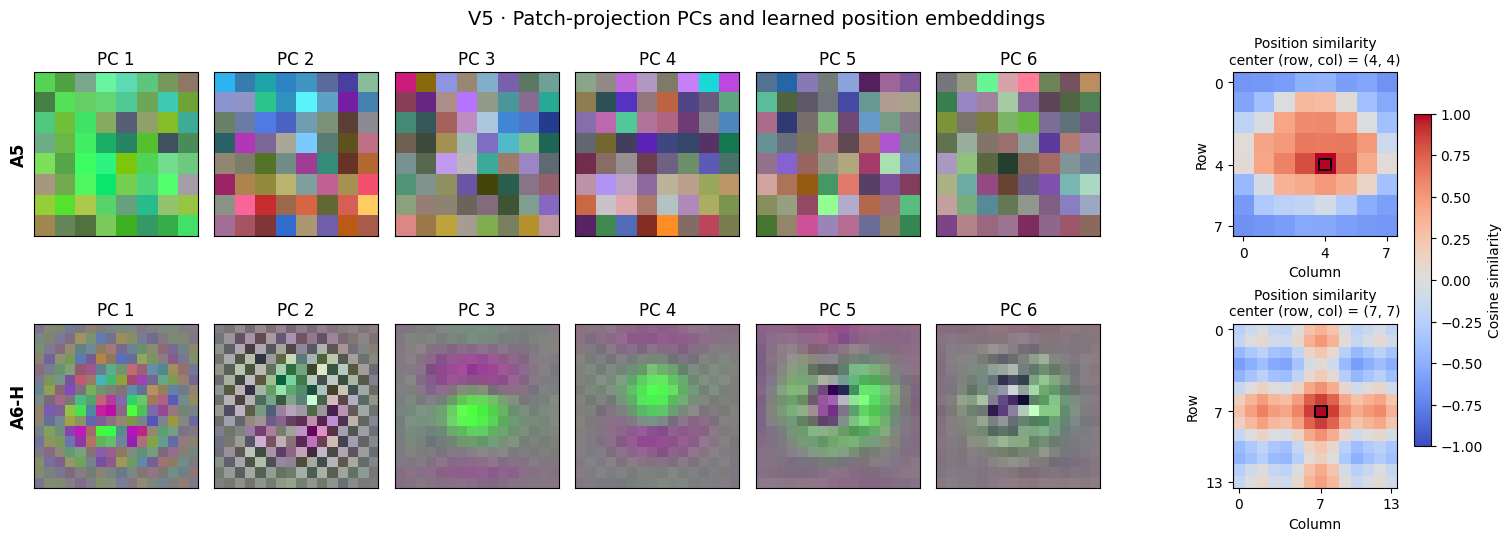

Saved: /content/drive/MyDrive/p1/results/V5.png


In [26]:
# TODO V5 (hint: a CNN has local filters and 2D layout built in; a ViT must learn both. Did A5 and A6-H?):
# for A5 and A6-H, the first six principal components of the patch-projection weights (flatten each output
# channel's filter into a row of length 3*p*p, center the columns, show the top six directions as p x p RGB patches), and the
# cosine similarity of a central patch's position embedding (give its grid coordinates) to all others (class token excluded).
# Functions: model.patch_embed.proj.weight; model.pos_embed; np.linalg.svd(W - W.mean(0), full_matrices=False);
#    F.cosine_similarity(a, b, dim=-1)
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

for name in ("A5", "A6-H"):
    if reload_check.loc[name, "status"] != "PASS":
        raise RuntimeError(f"{name} must pass the reload check before V5.")

results_dir = Path(globals().get("RESULTS_DIR", Path(CKPT_DIR).parent / "results"))
results_dir.mkdir(parents=True, exist_ok=True)


def extract_v5(model, image_size):
    vit = next(
        (m for m in model.modules()
         if hasattr(m, "patch_embed") and hasattr(m, "pos_embed")),
        None,
    )
    if vit is None:
        raise ValueError("Could not find patch_embed and pos_embed in this model.")

    projection = getattr(vit.patch_embed, "proj", vit.patch_embed)
    if not isinstance(projection, torch.nn.Conv2d):
        raise TypeError(f"Expected a Conv2d patch projection, got {type(projection)}.")

    weights = projection.weight.detach().cpu().numpy()
    embed_dim, channels, patch_h, patch_w = weights.shape
    if channels != 3:
        raise ValueError(f"Expected three RGB input channels, got {channels}.")

    W = weights.reshape(embed_dim, -1).astype(np.float64)
    W_centered = W - W.mean(axis=0, keepdims=True)
    _, _, Vt = np.linalg.svd(W_centered, full_matrices=False)

    pcs = Vt[:6].copy()

    for pc in pcs:
        if pc[np.argmax(np.abs(pc))] < 0:
            pc *= -1

    pcs = pcs.reshape(6, channels, patch_h, patch_w).transpose(0, 2, 3, 1)

    peak = np.abs(pcs).max(axis=(1, 2, 3), keepdims=True)
    pc_images = np.clip(0.5 + 0.5 * pcs / np.maximum(peak, 1e-12), 0, 1)

    with torch.inference_mode():
        dummy = projection.weight.new_zeros(1, 3, image_size, image_size)
        grid_h, grid_w = projection(dummy).shape[-2:]

    pos = vit.pos_embed.detach().float().cpu()
    if pos.ndim == 3 and pos.shape[0] == 1:
        pos = pos[0]

    n_patches = grid_h * grid_w
    if pos.ndim != 2 or pos.shape[0] != n_patches + 1:
        raise ValueError(
            f"Expected one CLS token plus {n_patches} patch positions, "
            f"got position embedding shape {tuple(pos.shape)}."
        )

    patch_pos = pos[1:]
    center_row, center_col = grid_h // 2, grid_w // 2
    center_idx = center_row * grid_w + center_col

    similarity = F.cosine_similarity(
        patch_pos,
        patch_pos[center_idx].unsqueeze(0),
        dim=-1,
    ).reshape(grid_h, grid_w).numpy()

    return pc_images, similarity, (center_row, center_col)


models_v5 = [
    ("A5", A5_MODEL, 64),
    ("A6-H", A6_H_MODEL, 224),
]

fig, axes = plt.subplots(
    2, 7,
    figsize=(15, 5.3),
    gridspec_kw={"width_ratios": [1, 1, 1, 1, 1, 1, 1.65]},
    constrained_layout=True,
)

for row, (name, model, image_size) in enumerate(models_v5):
    pc_images, similarity, (r, c) = extract_v5(model.eval(), image_size)
    grid_h, grid_w = similarity.shape

    for j, pc_image in enumerate(pc_images):
        ax = axes[row, j]
        ax.imshow(pc_image, interpolation="nearest")
        ax.set_title(f"PC {j + 1}")
        ax.set_xticks([])
        ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(name, fontsize=12, fontweight="bold")

    ax = axes[row, 6]
    heatmap = ax.imshow(
        similarity, cmap="coolwarm", vmin=-1, vmax=1,
        origin="upper", interpolation="nearest",
    )
    ax.scatter(c, r, marker="s", s=70, facecolors="none",
               edgecolors="black", linewidths=1.4)
    ax.set_title(f"Position similarity\ncenter (row, col) = ({r}, {c})", fontsize=10)
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")
    ax.set_xticks(sorted({0, c, grid_w - 1}))
    ax.set_yticks(sorted({0, r, grid_h - 1}))

    print(
        f"{name}: patch = {pc_images.shape[1]}×{pc_images.shape[2]}, "
        f"grid = {grid_h}×{grid_w}, center = ({r}, {c}), "
        f"self-similarity = {similarity[r, c]:.4f}"
    )

fig.colorbar(heatmap, ax=axes[:, 6].tolist(), shrink=0.8, label="Cosine similarity")
fig.suptitle("V5 · Patch-projection PCs and learned position embeddings", fontsize=14)

output_path = results_dir / "V5.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", output_path)